# 02 - Modelo supervisionado: o aluno será alfabetizado?

**Pergunta:** dado o contexto em que uma criança estuda (rede, município, UF, infraestrutura e
docentes das escolas, trajetória escolar da rede, nível socioeconômico), qual a probabilidade de
ela atingir 743 pontos ao final do 2º ano?

O treino é feito por `python -m src.modeling.treinar_aluno`, que leva ~10 min. Este notebook
carrega os artefatos gerados (`models/`, `reports/`, `data/gold/predicoes_aluno_2024.parquet`) e
documenta cada etapa do pipeline.

| Etapa | Implementação | Arquivo |
|---|---|---|
| Base e split temporal | amostra de 300 mil alunos/ano; treino = 2023, teste = 2024 | `src/modeling/dados.py` |
| Imputação | `SimpleImputer(median, add_indicator=True)` | `src/modeling/pipeline.py` |
| Transformação numérica | `StandardScaler` (só na logística) | `src/modeling/pipeline.py` |
| Encoding categórico | `OneHotEncoder(handle_unknown="ignore", min_frequency=20)` | `src/modeling/pipeline.py` |
| Modelos | regressão logística (baseline), HistGradientBoosting, LightGBM e LightGBM ponderado pelo peso amostral | `src/modeling/pipeline.py` |
| Validação | `GroupKFold(5)` por município + `RandomizedSearchCV` | `src/modeling/treinar_aluno.py` |
| Métricas | ROC-AUC, PR-AUC, F1, recall dos não alfabetizados, calibração | `src/evaluation/metricas.py` |

In [1]:
import sys
import json
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import joblib
import numpy as np
import pandas as pd
from sklearn import set_config

from src.config import DIR_GOLD, DIR_MODELOS, DIR_REPORTS
from src.evaluation import metricas as m
from src.visualization import graficos as g

g.configurar_estilo()
set_config(display="diagram")
pd.set_option("display.float_format", "{:.4f}".format)

artefato = joblib.load(DIR_MODELOS / "modelo_aluno_lgbm.joblib")
lgbm, limiar = artefato["pipeline"], artefato["limiar"]
resumo = json.loads((DIR_REPORTS / "metricas_modelo_aluno.json").read_text(encoding="utf-8"))
pred = pd.read_parquet(DIR_GOLD / "predicoes_aluno_2024.parquet")
print(f"{len(artefato['numericas'])} features numéricas + {len(artefato['categoricas'])} categóricas: {artefato['categoricas']}")

47 features numéricas + 3 categóricas: ['sigla_uf', 'nome_regiao', 'rede_nome']


## 1. O pipeline

Pré-processamento e modelo formam um objeto só. Em cada fold da validação cruzada, a mediana da
imputação e as categorias do one-hot são aprendidas **apenas com os dados de treino do fold**.
É assim que o pipeline evita vazar informação da validação para o treino.

In [2]:
lgbm

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int8](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](50,)","['escolas_com_2_ano','matriculas_2_ano','pct_alunos_escola_rural',..., 'sigla_uf','nome_regiao','rede_nome']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,50
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. I

## 2. Prevenção de data leakage

1. **Alvo fora das features:** `proficiencia` e `alfabetizado` (da fonte) nunca entram. O resultado
   agregado do próprio ano (`alunos_avaliados`, `taxa_alfabetizacao`) também foi excluído.
2. **Features anteriores à prova:** Censo de maio do mesmo ano; indicadores de 2022; INSE, PIB e
   população da edição anterior.
3. **Split temporal:** o modelo nunca vê 2024 durante treino, tuning ou escolha do limiar.
4. **GroupKFold por município:** alunos do mesmo município e rede têm features idênticas. Um
   `KFold` aleatório colocaria esses "gêmeos" no treino e na validação ao mesmo tempo e inflaria a
   métrica. Agrupando, a validação mede a capacidade de generalizar para **municípios novos**.

In [3]:
print("features numéricas usadas:")
print(", ".join(artefato["numericas"]))
proibidas = {"proficiencia", "alfabetizado", "taxa_alfabetizacao", "alunos_avaliados", "alunos_alfabetizados", "taxa_ano_anterior"}
assert not proibidas & set(artefato["numericas"] + artefato["categoricas"]), "feature com leakage!"
print("\nOK: nenhuma variável derivada do resultado da prova entre as features.")

features numéricas usadas:
escolas_com_2_ano, matriculas_2_ano, pct_alunos_escola_rural, pct_alunos_area_diferenciada, pct_biblioteca_ou_sala_leitura, pct_agua_potavel, pct_esgoto_rede_publica, pct_internet_alunos, pct_banda_larga, pct_laboratorio_informatica, pct_quadra_esportes, pct_parque_infantil, pct_material_pedagogico_infantil, pct_coordenador_pedagogico, pct_psicologo, pct_bibliotecario, pct_educacao_indigena, alunos_por_turma_ai, alunos_por_docente_ai, pct_matricula_integral_ai, pct_residencia_rural, pct_transporte_escolar, tamanho_medio_escola, atu_ef_2_ano, had_ef_anos_iniciais, tdi_ef_anos_iniciais, taxa_aprovacao_ef_2_ano, taxa_abandono_ef_anos_iniciais, dsu_ef_anos_iniciais, afd_ef_anos_iniciais_grupo_1, inse_medio, pct_alunos_inse_baixo, pib_per_capita, log_populacao, idhm, idhm_e, idhm_l, idhm_r, indice_gini, renda_pc, prop_pobreza_criancas, taxa_analfabetismo_15_mais, taxa_criancas_dom_sem_fund, taxa_freq_4_5, pct_populacao_rural_2010, capital_uf, amazonia_legal

OK: n

## 3. Validação cruzada e otimização de hiperparâmetros

In [4]:
cv = resumo["validacao_cruzada"]
nomes_modelos = {"logistica": "logística", "hist_gradient_boosting": "HistGradientBoosting",
                 "lightgbm": "LightGBM (melhor da busca)", "lightgbm_ponderado": "LightGBM ponderado (peso_aluno)"}
pd.DataFrame({
    "AUC validação (média)": {rotulo: cv[nome]["auc"][0] for nome, rotulo in nomes_modelos.items()},
    "desvio entre folds": {rotulo: cv[nome]["auc"][1] for nome, rotulo in nomes_modelos.items()},
    "AUC ponderado (validação)": {rotulo: cv[nome]["auc_ponderado"][0] for nome, rotulo in nomes_modelos.items()},
    "AUC treino (média)": {rotulo: cv[nome]["auc_treino"] for nome, rotulo in nomes_modelos.items()},
})

,AUC validação (média),desvio entre folds,AUC ponderado (validação),AUC treino (média)
logística,0.6468,0.0143,0.6451,0.6540
HistGradientBoosting,0.6475,0.0079,0.6457,0.6820
LightGBM (melhor da busca),0.6480,0.0082,0.6463,0.6798
LightGBM ponderado (peso_aluno),0.6473,0.0079,0.6457,0.6793


In [5]:
busca = pd.read_csv(DIR_REPORTS / "busca_hiperparametros_lgbm.csv")
colunas = [c for c in busca.columns if c.startswith("param_")] + ["mean_train_score", "mean_test_score", "std_test_score"]
tabela_busca = busca[colunas].rename(columns=lambda c: c.replace("param_modelo__", ""))
tabela_busca["gap_treino_validacao"] = tabela_busca["mean_train_score"] - tabela_busca["mean_test_score"]
tabela_busca.round(4)

,colsample_bytree,learning_rate,min_child_samples,n_estimators,num_leaves,reg_lambda,mean_train_score,mean_test_score,std_test_score,gap_treino_validacao
0,0.9547,0.0202,921,587,16,0.9513,0.6798,0.6480,0.0082,0.0318
1,0.5909,0.0164,509,513,36,0.1038,0.6870,0.6479,0.0086,0.0391
2,0.7229,0.0131,508,287,114,0.2132,0.6910,0.6470,0.0093,0.0440
3,0.8254,0.0117,393,691,44,0.3080,0.6900,0.6469,0.0082,0.0431
4,0.9300,0.0631,890,366,32,15.2551,0.6955,0.6447,0.0079,0.0508
5,0.6205,0.0636,477,708,22,0.1200,0.6979,0.6447,0.0075,0.0532
6,0.5115,0.0414,560,675,74,0.6966,0.7000,0.6428,0.0090,0.0572
7,0.6040,0.0465,526,601,104,1.0837,0.7005,0.6422,0.0097,0.0583
8,0.7280,0.0838,612,766,78,1.1859,0.7010,0.6404,0.0094,0.0606
9,0.9828,0.0893,826,545,67,0.3399,0.7006,0.6404,0.0070,0.0602


**Leitura:**
- **Os quatro candidatos empatam na validação cruzada** (AUC entre 0,647 e 0,648). Os modelos de boosting são **mais estáveis entre folds** (desvio de 0,008 contra 0,014 da logística).
- **O AUC ponderado pelo peso amostral** fica ~0,002 abaixo do simples em todos os modelos, sem mudar a ordem entre eles.
- **Overfitting controlado:** na busca do LightGBM, a configuração escolhida é a mais conservadora, com árvores rasas (16 folhas), mínimo de 921 alunos por folha e aprendizado lento. Ela tem o **menor gap entre treino e validação (0,03)**. As configurações mais complexas da tabela chegam a 0,70 no treino, mas pioram na validação, o sinal clássico de overfitting.
- `min_child_samples` alto faz sentido aqui: as features são de município × rede, e folhas pequenas decorariam municípios específicos em vez de aprender padrões.

## 4. Avaliação no teste (avaliação de 2024, nunca vista)

In [6]:
tabela_teste = pd.DataFrame(resumo["teste_2024"]).T
tabela_teste

,roc_auc,roc_auc_ponderado,pr_auc_alfabetizado,pr_auc_nao_alfabetizado,brier,f1_macro,recall_nao_alfabetizado,precisao_nao_alfabetizado,recall_alfabetizado,limiar
"logistica (limiar 0,5)",0.6210,0.6180,0.7050,0.5161,0.2292,0.5491,0.2664,0.5723,0.8664,0.5000
"hist_gradient_boosting (limiar 0,5)",0.6306,0.6275,0.7143,0.5257,0.2271,0.5586,0.2862,0.5765,0.8588,0.5000
"lightgbm (limiar 0,5)",0.6307,0.6277,0.7140,0.5258,0.2271,0.5610,0.2936,0.5742,0.8539,0.5000
"lightgbm_ponderado (limiar 0,5)",0.6301,0.6271,0.7138,0.5251,0.2272,0.5628,0.2993,0.5724,0.8499,0.5000
lightgbm (limiar 0.645),0.6307,0.6277,0.7140,0.5258,0.2271,0.5329,0.7801,0.4552,0.3733,0.6450


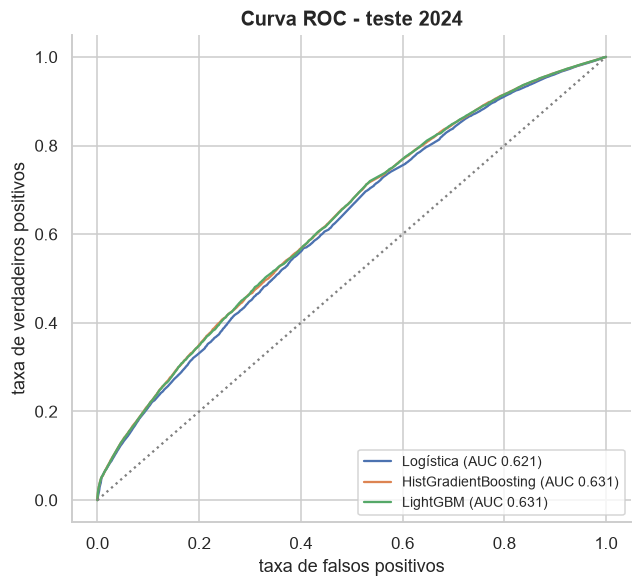

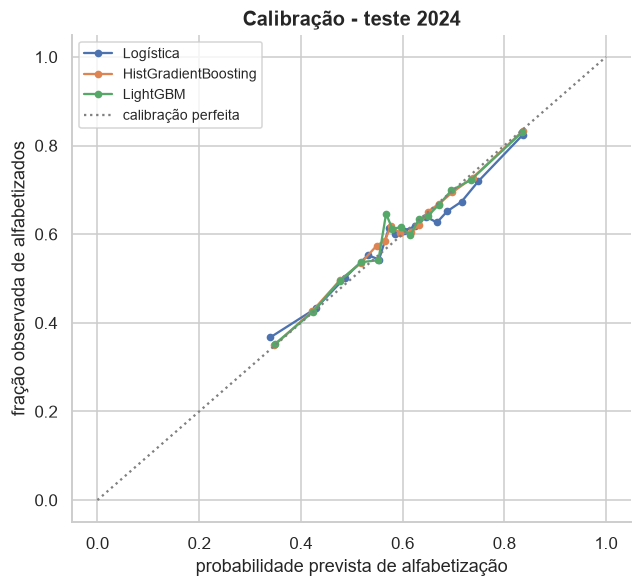

In [7]:
curvas = {"Logística": (pred["alfabetizado"], pred["proba_logistica"]),
          "HistGradientBoosting": (pred["alfabetizado"], pred["proba_hgb"]),
          "LightGBM": (pred["alfabetizado"], pred["proba_lgbm"])}
m.grafico_roc(curvas, salvar="mod_01_roc");
m.grafico_calibracao(curvas, salvar="mod_02_calibracao");

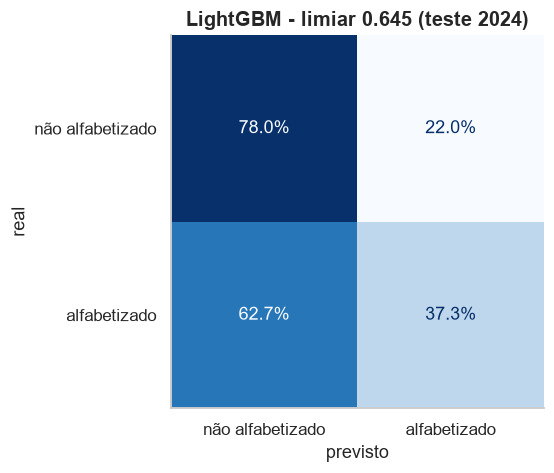

In [8]:
m.grafico_matriz_confusao(pred["alfabetizado"], pred["proba_lgbm"], limiar,
                          titulo=f"LightGBM - limiar {limiar} (teste 2024)", salvar="mod_03_matriz_confusao");

**Leitura:**
- **Generalização temporal:** o AUC caiu de 0,648 (validação 2023) para 0,631 (teste 2024). Uma queda pequena é esperada, porque 2024 traz mudanças que o modelo não viu, como a queda no Sul, com as enchentes no RS, e a melhora no Centro-Oeste. O modelo generaliza, com uma perda moderada.
- **Os modelos de boosting** (LightGBM e HistGradientBoosting) superam a logística em todas as métricas do teste, inclusive no **AUC ponderado pelo peso amostral**, e empatam entre si.
- **Calibração:** as curvas seguem a diagonal. Quando o modelo diz 70%, cerca de 70% daquele grupo se alfabetiza. Isso é essencial para o uso estratégico: somando as probabilidades por município, obtemos uma **taxa esperada** confiável.
- **Limiar de decisão:** com o padrão de 0,5, o modelo só identifica 29% dos não alfabetizados. Para política pública, deixar de identificar uma criança em risco custa mais do que um falso alarme. Por isso o limiar foi fixado **no treino** (0,645) para identificar 80% delas. No teste, ele identificou **78%**: a escolha feita só com 2023 se manteve em 2024. O custo é a precisão de 46%, contra os 40% de um sorteio, e mais falsos alarmes. É um uso de **triagem**, não de diagnóstico.

## 5. Quão bom pode ser este modelo? O teto do problema

Todas as features descrevem o **contexto** (município, rede, UF) e não o aluno. Duas crianças da
mesma rede, no mesmo município, recebem a mesma previsão. O limite superior é um "oráculo" que já
conhecesse a taxa **real** de 2024 de cada município × rede e a usasse como probabilidade.

In [9]:
teto = resumo["teto_teorico_auc"]
auc_lgbm = resumo["teste_2024"]["lightgbm (limiar 0,5)"]["roc_auc"]
auc_log = resumo["teste_2024"]["logistica (limiar 0,5)"]["roc_auc"]
print(f"AUC aleatório:          0.500")
print(f"AUC logística:          {auc_log:.3f}")
print(f"AUC LightGBM:           {auc_lgbm:.3f}")
print(f"AUC teto (oráculo):     {teto:.3f}")
print(f"\nO LightGBM captura {(auc_lgbm - 0.5) / (teto - 0.5):.0%} do sinal máximo disponível no nível município x rede.")

AUC aleatório:          0.500
AUC logística:          0.621
AUC LightGBM:           0.631
AUC teto (oráculo):     0.698

O LightGBM captura 66% do sinal máximo disponível no nível município x rede.


**Leitura - o resultado mais importante deste notebook:**

Um AUC de 0,63 parece baixo, mas o teto do problema com esses dados é de 0,70, e o modelo captura **dois terços do sinal possível**.

O que separa uma criança alfabetizada de outra **na mesma rede do mesmo município** (família, professora, turma, frequência) não está nos dados públicos. O `id_escola` é anonimizado e não há dados socioeconômicos individuais. A conclusão analítica é que **o contexto explica parte relevante do risco, mas não define o destino de cada criança**.

Na prática, isso orienta o uso do modelo:
- **No nível individual** ele serve como triagem: indica onde há mais chance de encontrar crianças em risco.
- **No nível agregado** (município × rede) ele é forte e bem calibrado. É o nível certo para **priorizar recursos**, explorado no notebook 04.

## 6. Desempenho por região e rede (o modelo é justo entre grupos?)

In [10]:
def resumo_grupo(df):
    return pd.Series({
        "alunos": len(df),
        "% não alfabetizados": 1 - df["alfabetizado"].mean(),
        "AUC": m.roc_auc_score(df["alfabetizado"], df["proba_lgbm"]) if df["alfabetizado"].nunique() > 1 else np.nan,
        "recall não alfab.": m.recall_score(df["alfabetizado"], (df["proba_lgbm"] >= limiar).astype(int), pos_label=0),
        "taxa real": df["alfabetizado"].mean(),
        "taxa prevista": df["proba_lgbm"].mean(),
    })

pd.concat({
    "região": pred.groupby("nome_regiao").apply(resumo_grupo, include_groups=False),
    "rede": pred.groupby("rede_nome").apply(resumo_grupo, include_groups=False),
})

alunos  % não alfabetizados    AUC  \
região Centro-Oeste  28156.0000               0.3525 0.6125   
       Nordeste      75264.0000               0.4307 0.7122   
       Norte         30517.0000               0.4948 0.5832   
       Sudeste      120747.0000               0.3764 0.5691   
       Sul           45316.0000               0.3882 0.6189   
rede   estadual      39145.0000               0.3742 0.5814   
       municipal    260855.0000               0.4057 0.6373   

                     recall não alfab.  taxa real  taxa prevista  
região Centro-Oeste             0.7862     0.6475         0.5893  
       Nordeste                 0.9169     0.5693         0.5482  
       Norte                    0.9730     0.5052         0.5037  
       Sudeste                  0.7671     0.6236         0.6101  
       Sul                      0.3923     0.6118         0.6818  
rede   estadual                 0.8070     0.6258         0.5960  
       municipal                0.7763     0.5943         0.5921

**Leitura:**
- **Nordeste (AUC 0,71):** é onde o modelo melhor separa os alunos, porque ali a desigualdade entre municípios é maior.
- **Sudeste (0,57):** os contextos são mais homogêneos, então há menos sinal entre redes.
- **Viés regional a acompanhar:** no **Sul**, o modelo previu 68% e o real foi 61%. Ele aprendeu o Sul de 2023 e não antecipou a queda de 2024 (enchentes no RS). Por isso o recall dos não alfabetizados lá é só 39%.
- **Centro-Oeste:** foi subestimado (59% previsto, 65% real), porque melhorou além do esperado.
- **Retreino:** choques como esses reforçam a necessidade de **retreinar o modelo a cada ciclo** de avaliação e de monitorar a calibração por região. Esses pontos estão em Limitações e evoluções futuras.

## 7. Escolha do algoritmo

Quatro candidatos foram comparados com a mesma validação (`GroupKFold` por município) e o mesmo teste:

| Critério | Logística | HistGradientBoosting | **LightGBM** | LightGBM ponderado |
|---|---|---|---|---|
| AUC validação (desvio) | 0,647 (0,014) | 0,648 (0,008) | **0,648 (0,008)** | 0,647 (0,008) |
| AUC teste 2024 | 0,621 | 0,631 | **0,631** | 0,630 |
| AUC teste **ponderado** (`peso_aluno`) | 0,618 | 0,628 | **0,628** | 0,627 |
| PR-AUC (não alfabetizados) | 0,516 | 0,526 | **0,526** | 0,525 |
| Brier (calibração) | 0,229 | 0,227 | **0,227** | 0,227 |

**Leitura:**
- **LightGBM** é o modelo final: tem o melhor resultado (por margem mínima) e a busca de
  hiperparâmetros mais completa. Também tem integração nativa com o SHAP (notebook 03).
- **HistGradientBoosting**, um segundo método de boosting, chega ao **mesmo AUC**. Isso confirma
  que o limite está **nos dados** (teto de 0,70) e não no algoritmo. Trocar de modelo não traria ganho.
- **Treinar com o peso amostral do Inep** (`sample_weight=peso_aluno`) não muda o resultado, nem no
  AUC simples nem no ponderado. A conclusão vale para a **população** de alunos, não só para a amostra.
- A **regressão logística** fica 1 ponto atrás. A maior parte do sinal está em poucas relações
  quase lineares, e o ganho do boosting vem dos limiares (seção 5 do notebook 03).